In [1]:
import os
import splitfolders
import matplotlib.pyplot as plt
import cv2

In [2]:
input_folder  = r'C:\Users\piyus\Downloads\Intel Image Dataset\Intel Image Dataset'
output_folder = r'C:\Users\piyus\Downloads\scene_data_split'

In [3]:
classes = os.listdir(input_folder)
print(f'Number of classes: {len(classes)}\n')
print('Classes:')
for c in classes:
    print(f'  - {c}')

Number of classes: 6

Classes:
  - buildings
  - forest
  - glacier
  - mountain
  - sea
  - street


In [4]:
splitfolders.ratio(input_folder, output=output_folder, seed=42, ratio=(0.7, 0.15, 0.15))

Copying files: 3000 files [00:15, 187.68 files/s]


In [5]:
train_dir = os.path.join(output_folder, 'train')
val_dir   = os.path.join(output_folder, 'val')
test_dir  = os.path.join(output_folder, 'test')

In [6]:
print('TRAIN')
for c in classes:
    print(c, ':', len(os.listdir(os.path.join(train_dir, c))))

print('\nVALIDATION')
for c in classes:
    print(c, ':', len(os.listdir(os.path.join(val_dir, c))))

print('\nTEST')
for c in classes:
    print(c, ':', len(os.listdir(os.path.join(test_dir, c))))

TRAIN
buildings : 305
forest : 331
glacier : 387
mountain : 367
sea : 357
street : 350

VALIDATION
buildings : 65
forest : 71
glacier : 82
mountain : 78
sea : 76
street : 75

TEST
buildings : 67
forest : 72
glacier : 84
mountain : 80
sea : 77
street : 76


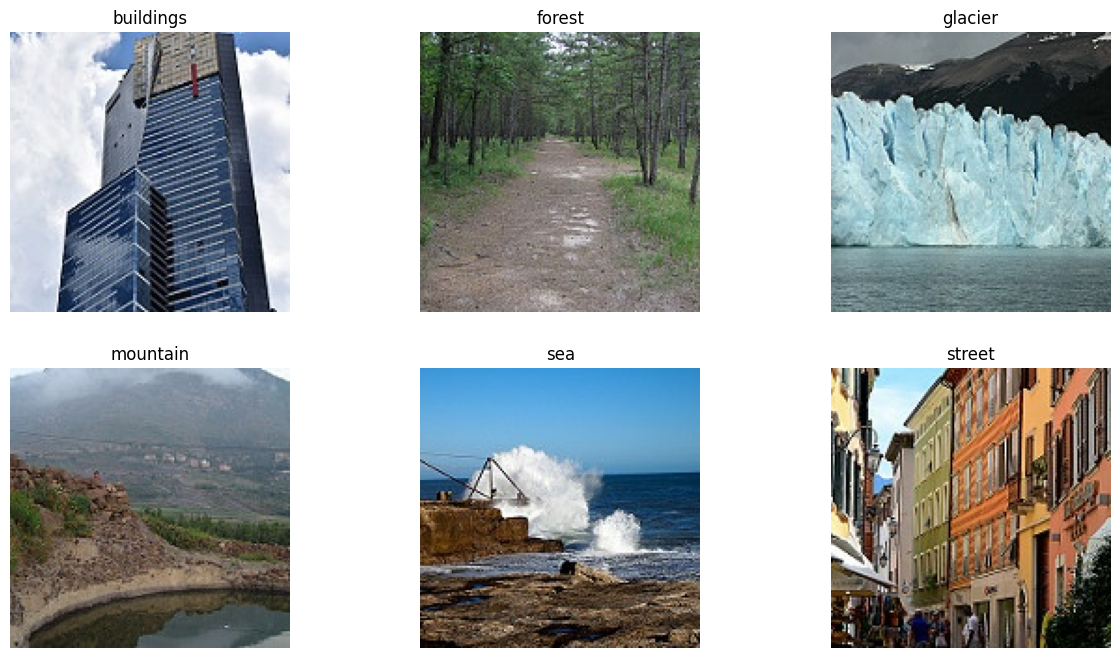

In [7]:
plt.figure(figsize=(15, 8))

for i, c in enumerate(classes):
    folder = os.path.join(train_dir, c)
    img = plt.imread(os.path.join(folder, os.listdir(folder)[0]))
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(c)
    plt.axis('off')

(150, 150, 3)


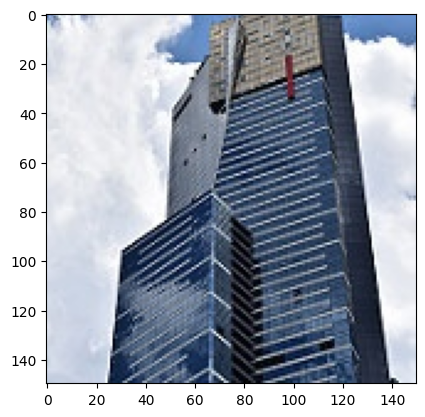

In [8]:
folder = os.path.join(train_dir, 'buildings')   # train_dir + class name
files = os.listdir(folder)                    # names of all files in it
img = plt.imread(os.path.join(folder, files[0]))   # folder + first file name

plt.imshow(img)
print(img.shape)

(150, 150, 3)


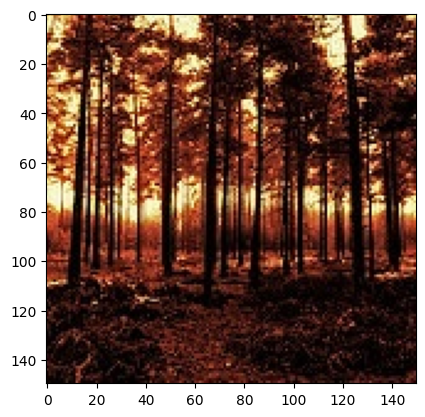

In [9]:
folder = os.path.join(train_dir, 'forest')
files = os.listdir(folder)
img = plt.imread(os.path.join(folder, files[9]))
plt.imshow(img)
print(img.shape)

(150, 150, 3)


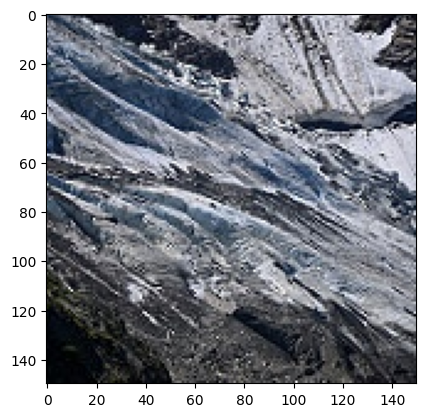

In [10]:
folder = os.path.join(train_dir, 'glacier')
files = os.listdir(folder)
img = plt.imread(os.path.join(folder, files[7]))
plt.imshow(img)
print(img.shape)

(150, 150, 3)


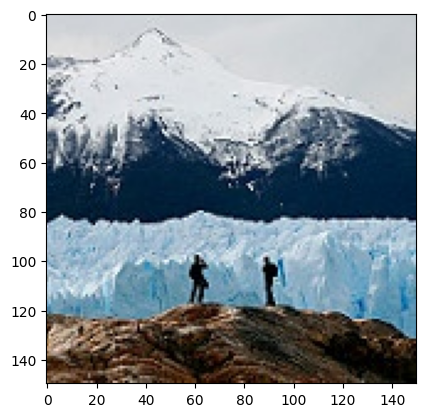

In [11]:
folder = os.path.join(train_dir, 'mountain')
files = os.listdir(folder)
img = plt.imread(os.path.join(folder, files[3]))
plt.imshow(img)
print(img.shape)

(150, 150, 3)


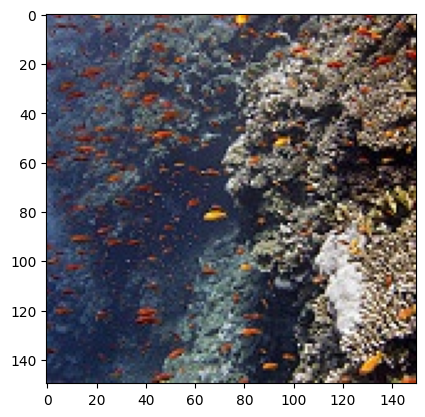

In [12]:
folder = os.path.join(train_dir, 'sea')
files = os.listdir(folder)
img = plt.imread(os.path.join(folder, files[1]))
plt.imshow(img)
print(img.shape)

(150, 150, 3)


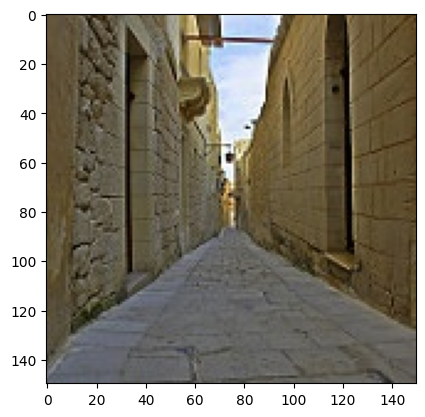

In [13]:
folder = os.path.join(train_dir, 'street')
files = os.listdir(folder)
img = plt.imread(os.path.join(folder, files[5]))
plt.imshow(img)
print(img.shape)

In [14]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1/255,
                                   rotation_range=20,
                                   width_shift_range=0.1,
                                   height_shift_range=0.1,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True,
                                   fill_mode='nearest')

In [15]:
test_datagen = ImageDataGenerator(rescale=1/255)

I am only augmenting the training images.Validation and test images are only rescaled.

In [26]:
image_size = (150,150)
batch_size = 32

In [27]:
train_generator = train_datagen.flow_from_directory(train_dir,
                                                    target_size = image_size,
                                                    batch_size = batch_size,
                                                    class_mode = 'categorical')

test_generator = test_datagen.flow_from_directory(test_dir,
                                                  target_size = image_size,
                                                  batch_size = batch_size,
                                                  class_mode = 'categorical',
                                                  shuffle = False)

val_generator = test_datagen.flow_from_directory(val_dir,
                                                 target_size = image_size,
                                                 batch_size = batch_size,
                                                 class_mode = 'categorical',
                                                 shuffle = False)

Found 2097 images belonging to 6 classes.
Found 456 images belonging to 6 classes.
Found 447 images belonging to 6 classes.


In [28]:
print(train_generator.class_indices)

{'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


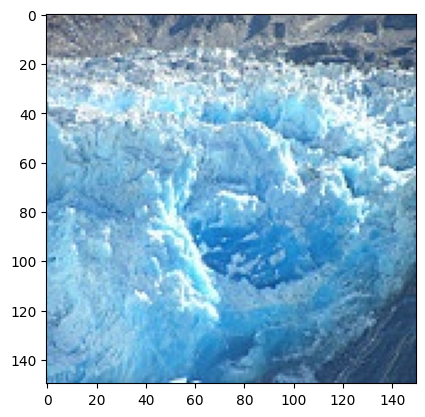

In [29]:
folder = os.path.join(train_dir, 'glacier')
files = os.listdir(folder)
glacier_img = plt.imread(os.path.join(folder, files[1]))

plt.imshow(glacier_img)

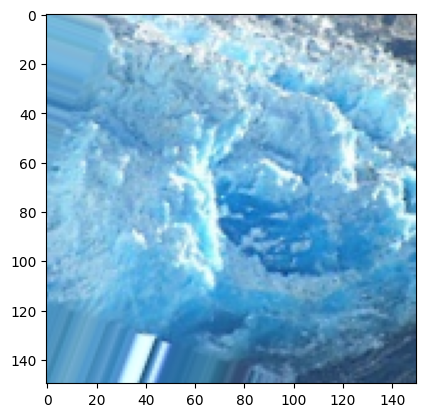

In [30]:
plt.imshow(train_datagen.random_transform(glacier_img))

So the augmentation steps are preprared for the training, testing and validation images.
We now go ahead with creating our CNN model.

In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [32]:
image_shape = (150,150,3)

model = Sequential()

model.add(Conv2D(filters = 32, kernel_size =(3,3), input_shape = image_shape, activation = 'relu'))
model.add(MaxPooling2D(pool_size = (2,2)))


model.add(Conv2D(filters = 64, kernel_size = (3,3), activation = 'relu'))
model.add(MaxPooling2D(pool_size = (2,2)))


model.add(Conv2D(filters = 64, kernel_size = (3,3), activation = 'relu'))
model.add(MaxPooling2D(pool_size = (2,2)))


model.add(Flatten())
model.add(Dense(128, activation = 'relu'))


model.add(Dropout(0.5))
model.add(Dense(6, activation = 'softmax'))



In [33]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 148, 148, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 74, 74, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 72, 72, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 36, 36, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 34, 34, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 17, 17, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 18496)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       2,367,616 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,424,710 (9.25 MB)

 Trainable params: 2,424,710 (9.25 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

I used categorical crossentropy because there are 6 classes in this project.

In [36]:
results = model.fit(train_generator,
                    epochs=20,
                    validation_data=val_generator)

Epoch 1/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 26s 387ms/step - accuracy: 0.5122 - loss: 1.2273 - val_accuracy: 0.5861 - val_loss: 1.0207
Epoch 2/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 25s 378ms/step - accuracy: 0.5618 - loss: 1.1290 - val_accuracy: 0.6040 - val_loss: 1.0492
Epoch 3/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 25s 379ms/step - accuracy: 0.5584 - loss: 1.1031 - val_accuracy: 0.6376 - val_loss: 1.0015
Epoch 4/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 26s 386ms/step - accuracy: 0.5885 - loss: 1.0671 - val_accuracy: 0.6465 - val_loss: 0.8698
Epoch 5/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 25s 383ms/step - accuracy: 0.6056 - loss: 1.0131 - val_accuracy: 0.6957 - val_loss: 0.8231
Epoch 6/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 28s 425ms/step - accuracy: 0.6381 - loss: 0.9618 - val_accuracy: 0.6801 - val_loss: 0.8273
Epoch 7/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 27s 405ms/step - accuracy: 0.6466 - loss: 0.9385 - val_accuracy: 0.6734 - val_loss: 0.8062
Epoch 8/20
66/66 ━━━━━━━━━━━━━━━━━━━━ 26s 386ms/step - accuracy: 0.6676 - loss: 0.8736 - val_accu

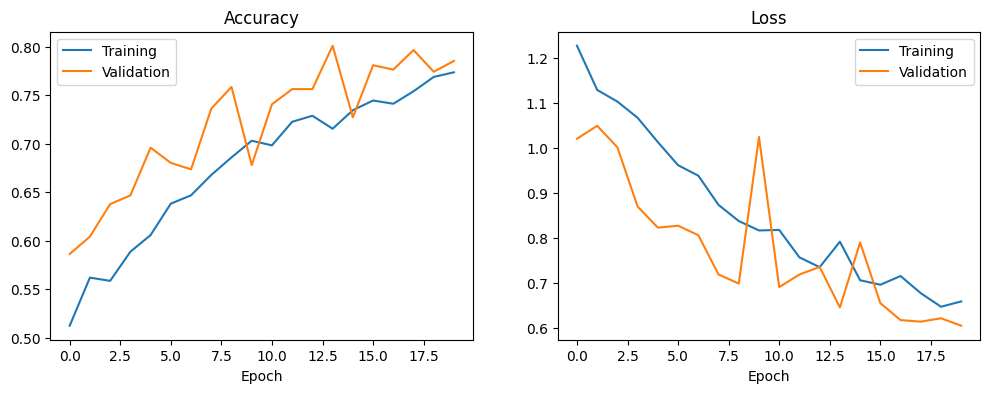

In [37]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(results.history['accuracy'], label='Training')
plt.plot(results.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(results.history['loss'], label='Training')
plt.plot(results.history['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.show()

### Training results
Accuracy rises and loss falls on both the training and validation sets. The two
curves stay close together, which means the model is not overfitting.

In [38]:
model.save('scene_cnn_model.keras')

In [39]:
test_loss, test_accuracy = model.evaluate(test_generator)

print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.2%}')

15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 745ms/step - accuracy: 0.8026 - loss: 0.6335
Test loss: 0.6335
Test accuracy: 80.26%


### Final test result
On the held-out test images, which the model had never seen, it reached an accuracy of 80.3%.

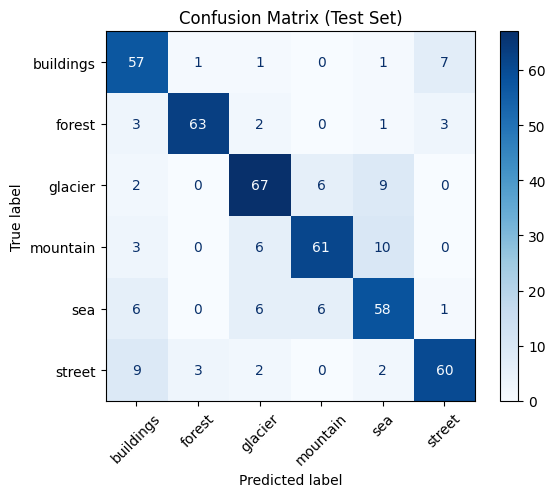

In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(true_classes, predicted_classes)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title('Confusion Matrix (Test Set)')
plt.show()

### Confusion matrix results
The model recognises forests best. Its most common mistakes are between street and
buildings, and between sea and the glacier and mountain scenes, which share similar
colours and large open areas.

In [44]:
from sklearn.metrics import classification_report

print(classification_report(true_classes, predicted_classes, target_names=class_names))

              precision    recall  f1-score   support

   buildings       0.71      0.85      0.78        67
      forest       0.94      0.88      0.91        72
     glacier       0.80      0.80      0.80        84
    mountain       0.84      0.76      0.80        80
         sea       0.72      0.75      0.73        77
      street       0.85      0.79      0.82        76

    accuracy                           0.80       456
   macro avg       0.81      0.80      0.80       456
weighted avg       0.81      0.80      0.80       456



### Predicting on a test iamge.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step


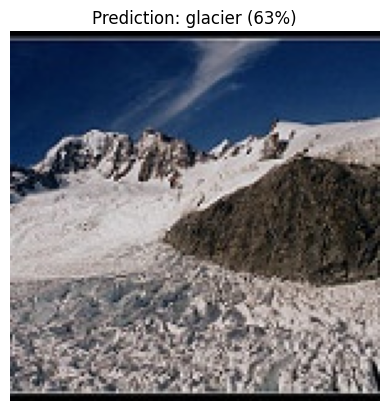

In [45]:
from tensorflow.keras.preprocessing import image

folder = os.path.join(test_dir, 'glacier')
file_name = os.listdir(folder)[0]
img = image.load_img(os.path.join(folder, file_name), target_size=(150, 150))

img_array = image.img_to_array(img)
img_array = test_datagen.standardize(img_array)
img_array = np.expand_dims(img_array, axis=0)

probs = model.predict(img_array)

plt.imshow(img)
plt.axis('off')
plt.title(f'Prediction: {class_names[np.argmax(probs)]} ({probs.max():.0%})')
plt.show()

# Conclusion

In this project I built a CNN from scratch to recognise six types of natural scenes: buildings, forest, glacier, mountain, sea and street. I used 3,000 images, split into 70% for training, 15% for validation and 15% for testing, and trained the model for 20 epochs.

On the 456 test images it had never seen, the model got about 80% of them right. It handled forests best, since their green texture is easy to spot. Sea was the hardest scene. The model often mixed it up with glaciers and mountains, which share a lot of blue and white, and it also confused streets with buildings, which often appear in the same photo.
